In [2]:
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers
import kagglehub

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Kích thước đầu vào của mô hình (cao x rộng). Ảnh gốc là 80 x 60 nên giữ tỉ lệ 3:4.
IMG_H, IMG_W = 96, 72

Tải dữ liệu và đọc `styles.csv`

In [3]:
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
print("Dữ liệu Kaggle đã sẵn sàng tại:", path)

100%|██████████| 565M/565M [03:20<00:00, 2.96MB/s] 

Extracting files...


Dữ liệu Kaggle đã sẵn sàng tại: C:\Users\ADMIN\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1


In [5]:
folder_data = Path(path)
print(list(folder_data.iterdir()))

[WindowsPath('C:/Users/ADMIN/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-small/versions/1/images'), WindowsPath('C:/Users/ADMIN/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-small/versions/1/myntradataset'), WindowsPath('C:/Users/ADMIN/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-small/versions/1/styles.csv')]


In [6]:
csv_path = folder_data / "styles.csv"
images_path = folder_data / "images"

print("styles.csv tồn tại:", csv_path.exists())
print("images tồn tại:", images_path.exists())

styles.csv tồn tại: True
images tồn tại: True


In [ ]:
fixed_csv = []
fixed_count = 0
short_rows = []

with open(csv_path, "r", encoding="utf-8-sig", newline="") as new_csv:
    line_row = csv.reader(new_csv)
    header = next(line_row)

    for line_number, row in enumerate(line_row, start=2):
        if len(row) > len(header):
            row = row[:9] + [", ".join(row[9:])]
            fixed_count += 1

        elif len(row) < len(header):
            short_rows.append((line_number, row))
            continue

        fixed_csv.append(row)

data = pd.DataFrame(fixed_csv, columns=header)

print("Số dòng đã sửa:", fixed_count)
print("Số dòng thiếu cột:", len(short_rows))
print("Kích thước dữ liệu:", data.shape)
print("Số cột sai sau xử lý:", sum(len(row) != len(header) for row in fixed_csv))
display(data.head())

Số dòng đã sửa: 22
Số dòng thiếu cột: 0
Kích thước dữ liệu: (44446, 10)
Số cột sai sau xử lý: 0


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012,Casual,Puma Men Grey T-shirt


Ghép ảnh với nhãn và làm sạch

In [8]:
def find_image(id):
    for ext in [".jpg", ".jpeg", ".png", ".webp"]:
        file_path = images_path / f"{int(id)}{ext}"
        if file_path.is_file():
            return str(file_path)
    return None

data["image_path"] = data["id"].apply(find_image)

missing_row = data["image_path"].isna().sum()
print("Số dòng không tìm thấy ảnh:", missing_row)

data = data.dropna(subset=["image_path"]).copy()

print("Số dòng còn lại:", len(data))
print("Số dòng thiếu ảnh sau xử lý:", data["image_path"].isna().sum())

Số dòng không tìm thấy ảnh: 5
Số dòng còn lại: 44441
Số dòng thiếu ảnh sau xử lý: 0


In [9]:
columns = data.select_dtypes(include=["object"]).columns
for column in columns:
    data[column] = data[column].str.strip()

print("ID bị thiếu:", data["id"].isna().sum())
print("ID trùng:", data["id"].duplicated().sum())
print("Nhãn articleType bị thiếu:", data["articleType"].isna().sum())

ID bị thiếu: 0
ID trùng: 0
Nhãn articleType bị thiếu: 0


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11084\774289935.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columns = data.select_dtypes(include=["object"]).columns


In [10]:
print("Số nhãn trong dataset:", data["articleType"].nunique())
print(data["articleType"].value_counts().head(15))

Số nhãn trong dataset: 142
articleType
Tshirts         7069
Shirts          3215
Casual Shoes    2846
Watches         2542
Sports Shoes    2036
Kurtas          1844
Tops            1762
Handbags        1759
Heels           1323
Sunglasses      1073
Wallets          936
Flip Flops       916
Sandals          897
Briefs           849
Belts            813
Name: count, dtype: int64


Chọn 10 nhãn

In [11]:
select_classes = [
    "Tshirts",
    "Shirts",
    "Tops",
    "Kurtas",
    "Jeans",
    "Casual Shoes",
    "Sports Shoes",
    "Heels",
    "Flip Flops",
    "Handbags",
]
data = data[data["articleType"].isin(select_classes)].copy()

print("Tổng số ảnh thuộc 10 nhãn:", len(data))
print("\nSố ảnh của từng nhãn:")
print(data["articleType"].value_counts().reindex(select_classes, fill_value=0))

Tổng số ảnh thuộc 10 nhãn: 23378

Số ảnh của từng nhãn:
articleType
Tshirts         7069
Shirts          3215
Tops            1762
Kurtas          1844
Jeans            608
Casual Shoes    2846
Sports Shoes    2036
Heels           1323
Flip Flops       916
Handbags        1759
Name: count, dtype: int64


Kiểm tra ảnh đọc được và đúng kích thước

In [12]:
def check_image(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:  # mở lại vì verify() làm đối tượng không dùng tiếp được
            return im.size          # (rộng, cao)
    except Exception:
        return None

data["size"] = [check_image(p) for p in tqdm(data["image_path"])]

print("Ảnh hỏng/không đọc được:", data["size"].isna().sum())
print("\nKích thước ảnh gốc (rộng, cao):")
print(data["size"].value_counts())

data = data.dropna(subset=["size"]).drop(columns="size").reset_index(drop=True)
print("\nSố ảnh còn lại:", len(data))

100%|██████████| 23378/23378 [04:54<00:00, 79.32it/s] 

Ảnh hỏng/không đọc được: 0

Kích thước ảnh gốc (rộng, cao):
size
(60, 80)    23372
(53, 80)        2
(60, 60)        2
(60, 75)        1
(60, 76)        1
Name: count, dtype: int64

Số ảnh còn lại: 23378


Chia train / validation / test và lưu `split.csv`

In [14]:
train_data, remain_data = train_test_split(
    data, test_size=0.30, random_state=RANDOM_STATE, stratify=data["articleType"])
val_data, test_data = train_test_split(
    remain_data, test_size=0.50, random_state=RANDOM_STATE, stratify=remain_data["articleType"])

# Mã hóa nhãn: thứ tự theo bảng chữ cái, dùng chung cho cả nhóm
class_names = sorted(select_classes)
label_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)

y_train = train_data["articleType"].map(label_to_idx).values
y_val = val_data["articleType"].map(label_to_idx).values
y_test = test_data["articleType"].map(label_to_idx).values

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print("Tổng:", len(train_data) + len(val_data) + len(test_data))
print("Thứ tự lớp:", class_names)

split_df = pd.concat([
    train_data.assign(split="train"),
    val_data.assign(split="val"),
    test_data.assign(split="test"),
])[["id", "articleType", "split"]]
split_df.to_csv("split.csv", index=False)
print("\nĐã lưu split.csv:", split_df.shape)

Train: 16364
Validation: 3507
Test: 3507
Tổng: 23378
Thứ tự lớp: ['Casual Shoes', 'Flip Flops', 'Handbags', 'Heels', 'Jeans', 'Kurtas', 'Shirts', 'Sports Shoes', 'Tops', 'Tshirts']

Đã lưu split.csv: (23378, 3)


Đọc ảnh, resize 96×72 và lưu cache

In [15]:
def load_images(df):
    X = np.zeros((len(df), IMG_H, IMG_W, 3), dtype="uint8")
    for i, p in enumerate(tqdm(df["image_path"])):
        with Image.open(p) as im:
            # PIL.resize nhận (rộng, cao)
            X[i] = np.asarray(im.convert("RGB").resize((IMG_W, IMG_H), Image.BILINEAR))
    return X

X_train = load_images(train_data)
X_val = load_images(val_data)
X_test = load_images(test_data)

print("X_train:", X_train.shape, X_train.dtype)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

100%|██████████| 3507/3507 [00:02<00:00, 1347.18it/s]

X_train: (16364, 96, 72, 3) uint8
X_val:   (3507, 96, 72, 3)
X_test:  (3507, 96, 72, 3)


In [ ]:
np.savez_compressed(
    "fashion_96x72.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test,
    class_names=np.array(class_names),
)
print("Đã lưu fashion_96x72.npz")

Đã lưu fashion_96x72.npz


Phân phối lớp và class weights

,train,val,test,total
Casual Shoes,1992,427,427,2846
Flip Flops,641,138,137,916
Handbags,1231,264,264,1759
Heels,926,199,198,1323
Jeans,426,91,91,608
Kurtas,1291,276,277,1844
Shirts,2251,482,482,3215
Sports Shoes,1425,305,306,2036
Tops,1233,264,265,1762
Tshirts,4948,1061,1060,7069


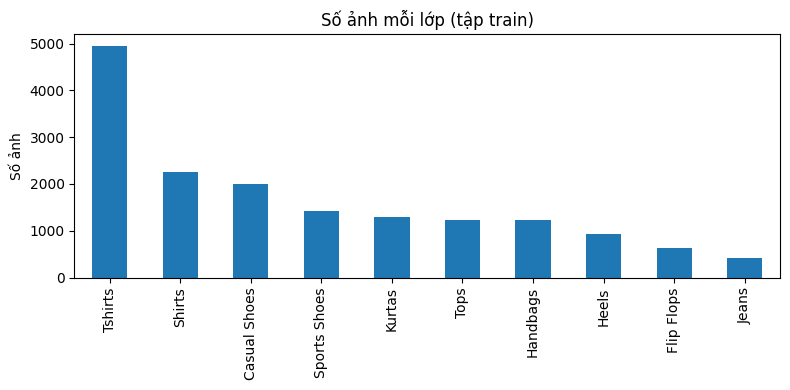

{'Casual Shoes': 0.82, 'Flip Flops': 2.55, 'Handbags': 1.33, 'Heels': 1.77, 'Jeans': 3.84, 'Kurtas': 1.27, 'Shirts': 0.73, 'Sports Shoes': 1.15, 'Tops': 1.33, 'Tshirts': 0.33}


In [17]:
dist = pd.DataFrame({
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "val": np.bincount(y_val, minlength=NUM_CLASSES),
    "test": np.bincount(y_test, minlength=NUM_CLASSES),
}, index=class_names)
dist["total"] = dist.sum(axis=1)
display(dist)

dist["train"].sort_values(ascending=False).plot(
    kind="bar", figsize=(8, 4), title="Số ảnh mỗi lớp (tập train)")
plt.ylabel("Số ảnh")
plt.tight_layout()
plt.show()

# Lớp nhiều ảnh (Tshirts) hơn lớp ít ảnh (Jeans) gần 12 lần -> dùng class weights khi train
w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(w))
print({class_names[k]: round(float(v), 2) for k, v in class_weight.items()})

Data augmentation (chỉ dùng khi train)

In [18]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="data_augmentation")

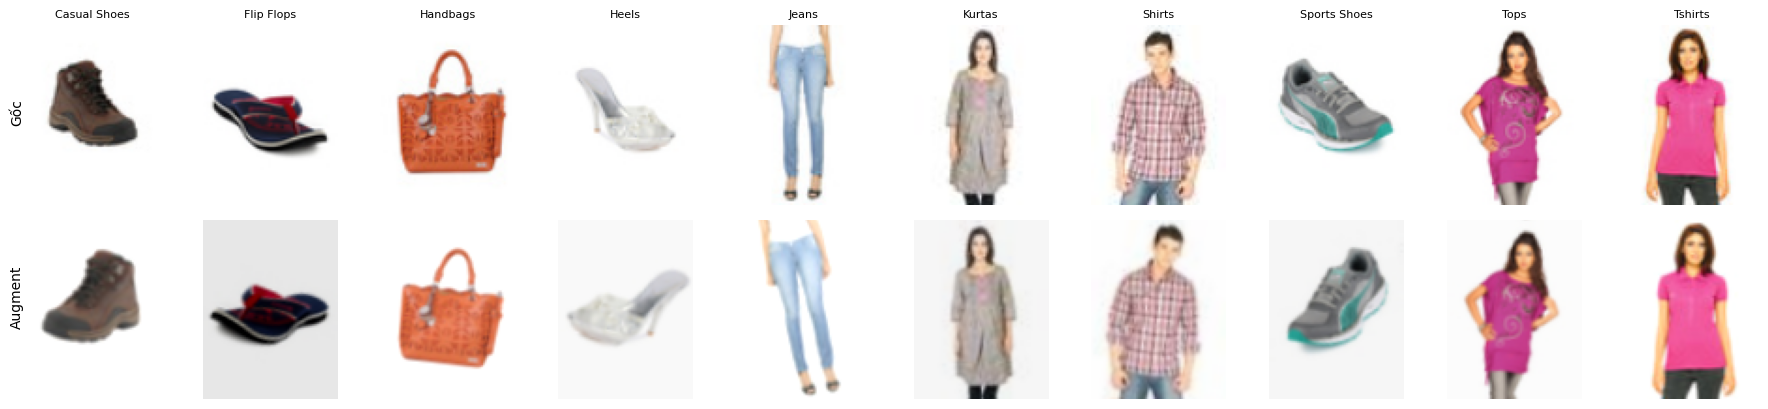

In [19]:
# Hình minh họa cho báo cáo: ảnh gốc (hàng trên) và sau augmentation (hàng dưới)
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(1.8 * NUM_CLASSES, 4.2))
for c in range(NUM_CLASSES):
    img = X_train[np.where(y_train == c)[0][0]]
    aug = data_augmentation(img[None].astype("float32"), training=True)[0].numpy()
    axes[0, c].imshow(img)
    axes[0, c].set_title(class_names[c], fontsize=8)
    axes[1, c].imshow(np.clip(aug, 0, 255).astype("uint8"))
    axes[0, c].axis("off")
    axes[1, c].axis("off")
fig.text(0.01, 0.72, "Gốc", rotation=90, va="center")
fig.text(0.01, 0.28, "Augment", rotation=90, va="center")
plt.tight_layout()
plt.show()